CMS Chronic Disease Analysis

Chronic Disease Analysis Using CMS Dataset

Project Overview
This analysis examines chronic disease prevalence, Medicare utilization, and payment patterns across the United States using data from the Centers for Medicare & Medicaid Services (CMS). 

We focus on:
- National and state-level disease prevalence patterns
- Medicare spending by chronic condition
- Comparative analysis of Texas, New York, California, and Florida

Data Source
- **Dataset**: CMS Chronic Conditions Data
- **URL**: https://data.cms.gov/
- **Geographic Levels**: National and State
- **Key Variables**: Prevalence (Prvlnc), Medicare Payments (Tot_Mdcr_Pymt_PC, Tot_Mdcr_Stdzd_Pymt_PC)

In [53]:
#import the requiered libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10


Loading dataset and preprocesssing

In [54]:
#load the dataset
df = pd.read_csv('chronic-disease-data.csv')
df['Prvlnc'] = df['Prvlnc'] * 100

# Filter for State and National level data only
df_filtered = df[df['Bene_Geo_Lvl'].isin(['State', 'National'])].copy()

# Display basic information
print("Dataset Shape:", df_filtered.shape)
print("\nColumn Names:")
print(df_filtered.columns.tolist())

# Check for missing values
print("\nMissing values in key columns:")
print(df_filtered[['Prvlnc', 'Tot_Mdcr_Stdzd_Pymt_PC', 'Tot_Mdcr_Pymt_PC']].isnull().sum())

# Remove rows where Prvlnc is NaN for prevalence analysis
df_with_prevalence = df_filtered[df_filtered['Prvlnc'].notna()].copy()
print(f"\nRows with valid prevalence data: {len(df_with_prevalence)}")

# Remove rows where payment data is NaN for payment analysis
df_with_payments = df_filtered[
    (df_filtered['Tot_Mdcr_Stdzd_Pymt_PC'].notna()) & 
    (df_filtered['Tot_Mdcr_Pymt_PC'].notna())
].copy()
print(f"Rows with valid payment data: {len(df_with_payments)}")

# Define target states
target_states = ['Texas', 'New York', 'California', 'Florida']





Dataset Shape: (32340, 12)

Column Names:
['Bene_Geo_Lvl', 'Bene_Geo_Desc', 'Bene_Geo_Cd', 'Bene_Age_Lvl', 'Bene_Demo_Lvl', 'Bene_Demo_Desc', 'Bene_Cond', 'Prvlnc', 'Tot_Mdcr_Stdzd_Pymt_PC', 'Tot_Mdcr_Pymt_PC', 'Hosp_Readmsn_Rate', 'ER_Visits_Per_1000_Benes']

Missing values in key columns:
Prvlnc                     3260
Tot_Mdcr_Stdzd_Pymt_PC    31207
Tot_Mdcr_Pymt_PC          31207
dtype: int64

Rows with valid prevalence data: 29080
Rows with valid payment data: 1133


# Goal 1: Measure Chronic Disease Prevalence by Age and Race

## Objective
Analyze how chronic disease prevalence varies across different demographic groups, including age ranges and racial/ethnic populations. This analysis helps identify which populations face the highest disease burden.

## Key Questions
1. Which chronic diseases are most prevalent nationally?
2. How does prevalence differ across age groups?
3. Are there racial/ethnic disparities in disease prevalence?
4. How do Texas, New York, California, and Florida compare to the national average?

In [55]:
# Filter for age-related data
df_age = df_with_prevalence[df_with_prevalence['Bene_Demo_Lvl'] == 'All'].copy()

# Filter for race-related data  
df_race = df_with_prevalence[df_with_prevalence['Bene_Demo_Lvl'] == 'Race'].copy()

print(f"Age-related records: {len(df_age)}")
print(f"Race-related records: {len(df_race)}")

Age-related records: 1133
Race-related records: 14587


## Visualization 1.1: National Chronic Disease Prevalence

### What This Shows
This bar chart displays the prevalence rates for the top 6 chronic diseases in the United States. Prevalence is measured as the percentage of Medicare beneficiaries diagnosed with each condition.

### Key Insights to Look For
- Which diseases affect the largest proportion of the population
- The relative burden of different chronic conditions
- Potential priorities for healthcare resource allocation

### Interpretation Guide
- **Higher bars** = More beneficiaries affected by the condition
- **Prevalence (%)** = Percentage of Medicare population with the diagnosis


Top 6 diseases: ['Hypertension', 'Hyperlipidemia', 'Arthritis', 'Diabetes', 'Ischemic Heart Disease', 'Chronic Kidney Disease']


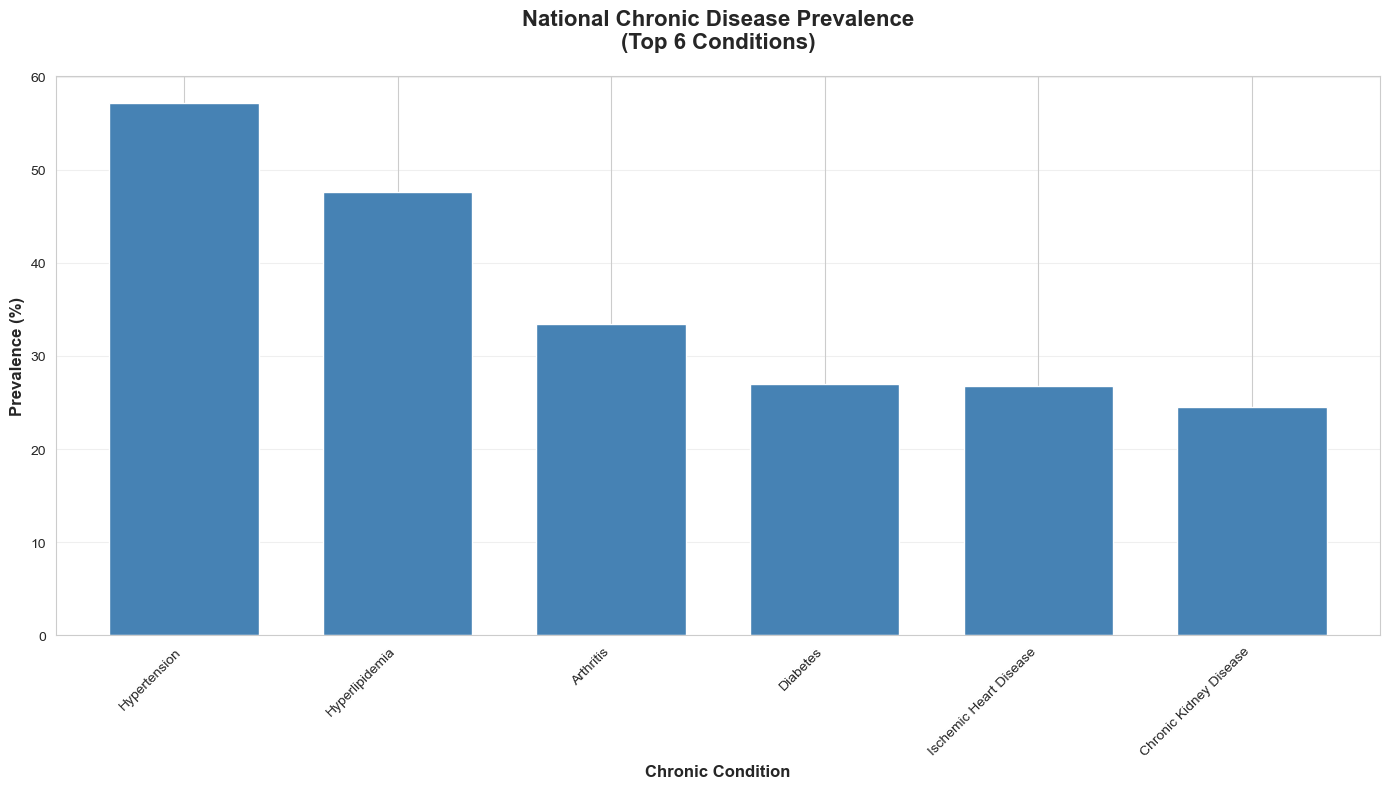


Summary: Disease prevalence patterns across the dataset
                 Bene_Cond Bene_Age_Lvl  Prvlnc
2                Arthritis          All   33.47
8   Chronic Kidney Disease          All   24.48
10                Diabetes          All   26.95
15          Hyperlipidemia          All   47.66
16            Hypertension          All   57.20
17  Ischemic Heart Disease          All   26.81


In [56]:
# Get national data for age groups
df_national_age = df_age[df_age['Bene_Geo_Lvl'] == 'National'].copy()


# Calculate average prevalence by disease and age level
prevalence_age = df_national_age.groupby(['Bene_Cond', 'Bene_Age_Lvl'])['Prvlnc'].mean().reset_index()

# Get top diseases
top_diseases = df_national_age.groupby('Bene_Cond')['Prvlnc'].mean().nlargest(6).index

print(f"\nTop 6 diseases: {top_diseases.tolist()}")

# Create visualization
if len(prevalence_age) > 0:
    fig, ax = plt.subplots(figsize=(14, 8))
    prevalence_age_top = prevalence_age[prevalence_age['Bene_Cond'].isin(top_diseases)]
    
    if len(prevalence_age_top) > 0 and 'Bene_Age_Lvl' in prevalence_age_top.columns:
        if (prevalence_age_top['Bene_Age_Lvl'] == 'All').all():
            disease_summary = prevalence_age_top.groupby('Bene_Cond')['Prvlnc'].mean().sort_values(ascending=False)
            disease_summary.plot(kind='bar', ax=ax, width=0.7, color='steelblue')
            ax.set_title('National Chronic Disease Prevalence\n(Top 6 Conditions)', 
                          fontsize=16, fontweight='bold', pad=20)
            ax.set_xlabel('Chronic Condition', fontsize=12, fontweight='bold')
            ax.set_ylabel('Prevalence (%)', fontsize=12, fontweight='bold')
            ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
        else:
            prevalence_pivot = prevalence_age_top.pivot(index='Bene_Age_Lvl', columns='Bene_Cond', values='Prvlnc')
            prevalence_pivot = prevalence_pivot.fillna(0)
            prevalence_pivot.plot(kind='bar', ax=ax, width=0.8)
            ax.set_title('National Chronic Disease Prevalence by Age Group\n(Top 6 Conditions)', 
                          fontsize=16, fontweight='bold', pad=20)
            ax.set_xlabel('Age Group', fontsize=12, fontweight='bold')
            ax.set_ylabel('Prevalence (%)', fontsize=12, fontweight='bold')
            ax.legend(title='Chronic Condition', bbox_to_anchor=(1.05, 1), loc='upper left')
            ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
        
        ax.grid(axis='y', alpha=0.3)
        plt.tight_layout()
        plt.savefig('prevalence_by_age.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        print("\nSummary: Disease prevalence patterns across the dataset")
        print(prevalence_age_top.head(10))

## Visualization 1.2: Disease Prevalence by Race/Ethnicity

### What This Shows
This heatmap reveals how chronic disease prevalence varies across different racial and ethnic groups. Each cell represents the percentage of beneficiaries in that racial/ethnic group with the specified condition.

### Key Insights to Look For
- **Health disparities**: Which racial/ethnic groups face higher disease burdens
- **Disease-specific patterns**: Some conditions may show greater disparities than others
- **Color intensity**: Darker red indicates higher prevalence

### Clinical Significance
Understanding these disparities can help healthcare systems:
- Develop targeted intervention programs
- Allocate culturally appropriate resources
- Address social determinants of health

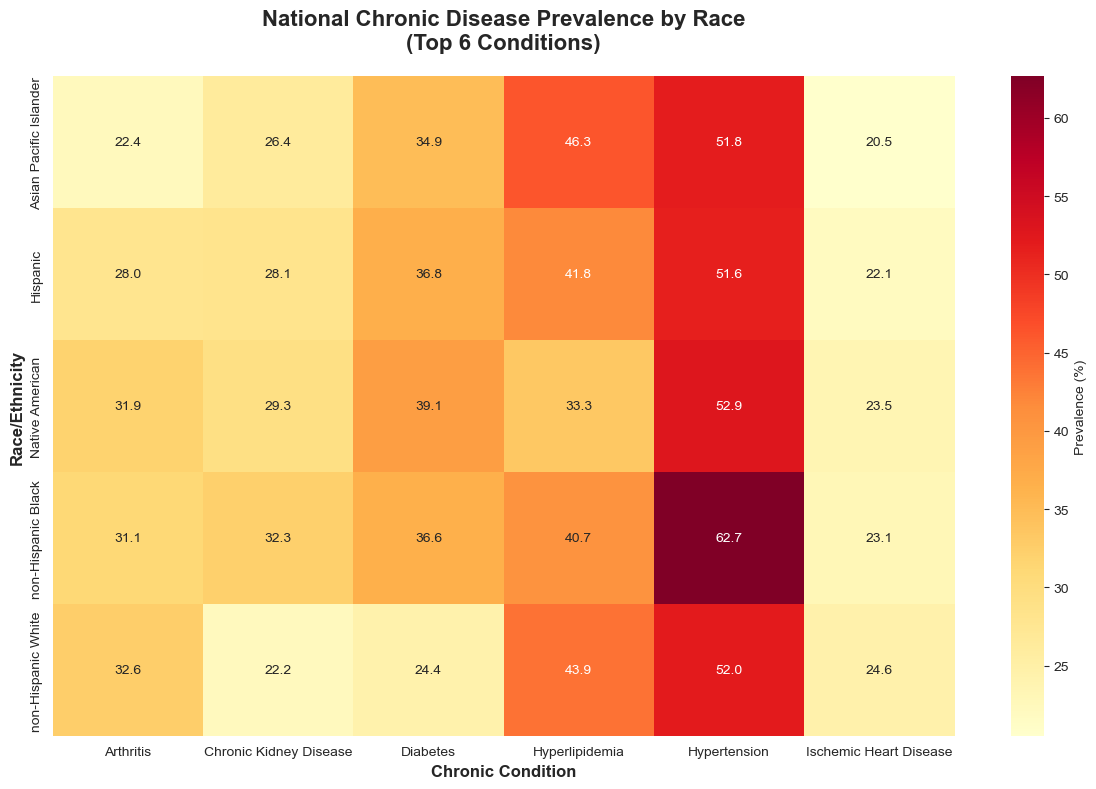


Summary: Prevalence varies across racial groups, with notable disparities in certain conditions.
Bene_Cond               Arthritis  Chronic Kidney Disease  Diabetes  \
Bene_Demo_Desc                                                        
Asian Pacific Islander      22.45                   26.40     34.89   
Hispanic                    27.98                   28.13     36.75   
Native American             31.93                   29.33     39.14   
non-Hispanic Black          31.12                   32.26     36.61   
non-Hispanic White          32.65                   22.22     24.38   

Bene_Cond               Hyperlipidemia  Hypertension  Ischemic Heart Disease  
Bene_Demo_Desc                                                                
Asian Pacific Islander           46.27         51.84                   20.48  
Hispanic                         41.84         51.59                   22.12  
Native American                  33.33         52.87                   23.50  
non-Hispa

In [57]:
# Get national data for race
df_national_race = df_race[df_race['Bene_Geo_Lvl'] == 'National'].copy()

# Calculate average prevalence by disease and race
prevalence_race = df_national_race.groupby(['Bene_Cond', 'Bene_Demo_Desc'])['Prvlnc'].mean().reset_index()

# Get top diseases
prevalence_race_top = prevalence_race[prevalence_race['Bene_Cond'].isin(top_diseases)]

# Create heatmap
if len(prevalence_race_top) > 0:
    fig, ax = plt.subplots(figsize=(12, 8))
    prevalence_race_pivot = prevalence_race_top.pivot(index='Bene_Demo_Desc', columns='Bene_Cond', values='Prvlnc')
    prevalence_race_pivot = prevalence_race_pivot.fillna(0)
    
    if not prevalence_race_pivot.empty and prevalence_race_pivot.notna().any().any():
        sns.heatmap(prevalence_race_pivot, annot=True, fmt='.1f', cmap='YlOrRd', 
                    cbar_kws={'label': 'Prevalence (%)'}, ax=ax)
        ax.set_title('National Chronic Disease Prevalence by Race\n(Top 6 Conditions)', 
                     fontsize=16, fontweight='bold', pad=20)
        ax.set_xlabel('Chronic Condition', fontsize=12, fontweight='bold')
        ax.set_ylabel('Race/Ethnicity', fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.savefig('prevalence_by_race.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        print("\nSummary: Prevalence varies across racial groups, with notable disparities in certain conditions.")
        print(prevalence_race_pivot.round(2))

## Visualization 1.3: State vs National Prevalence Comparison

### What This Shows
This grouped bar chart compares chronic disease prevalence rates in Texas, New York, California, and Florida against the national average for the top 4 conditions.

### Key Insights to Look For
- **State variations**: Which states have higher or lower prevalence than the national average
- **Regional patterns**: Geographic clustering of disease burden
- **Resource needs**: States with higher prevalence may need additional healthcare resources

### How to Read This Chart
- Each disease has 5 bars (National + 4 target states)
- Compare each state's bar height to the National bar
- Higher bars indicate greater disease prevalence in that state

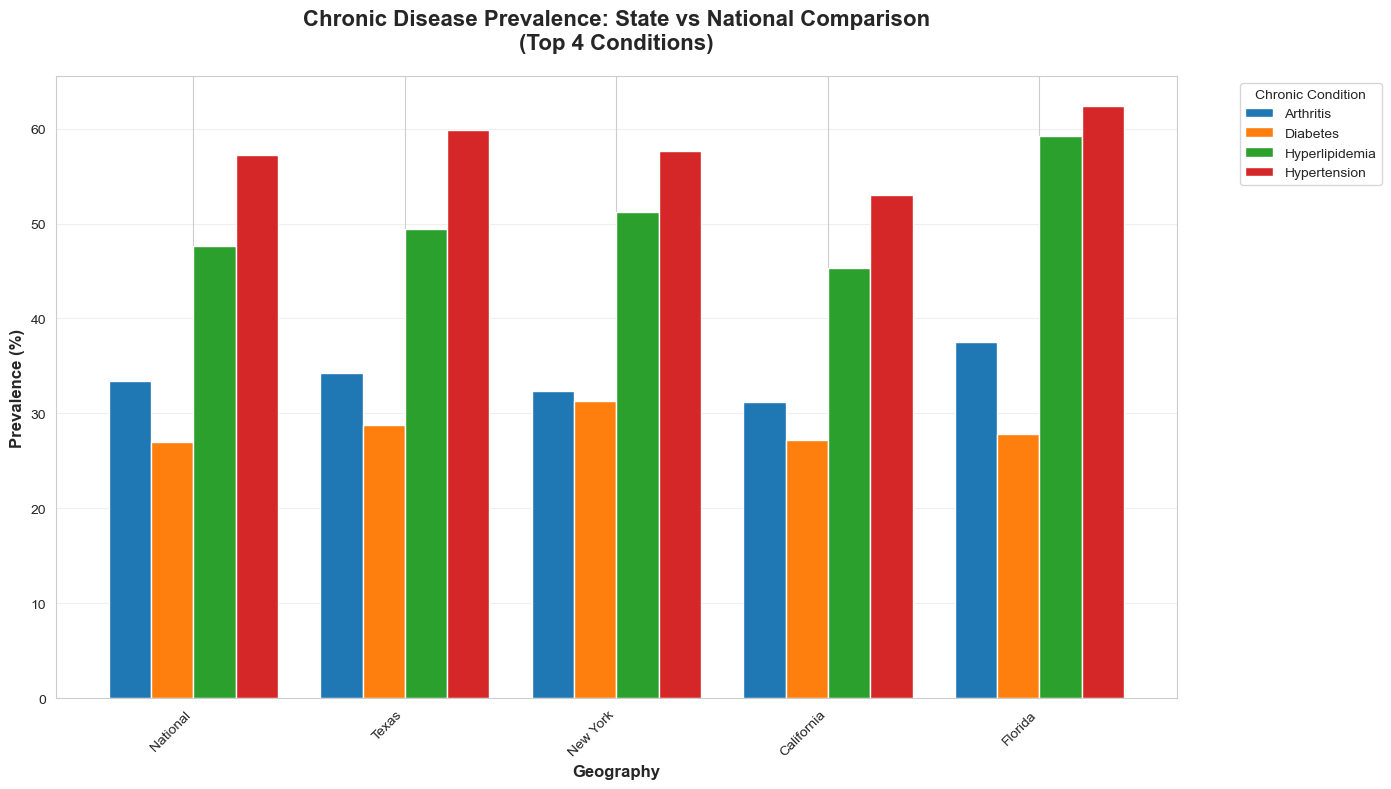


State vs National Prevalence Comparison:
Bene_Cond      Arthritis  Diabetes  Hyperlipidemia  Hypertension
Bene_Geo_Desc                                                   
National           33.47     26.95           47.66         57.20
Texas              34.21     28.79           49.47         59.87
New York           32.32     31.34           51.16         57.67
California         31.18     27.19           45.29         52.96
Florida            37.51     27.81           59.19         62.38


In [58]:
# Get data for target states and national
df_states_comp = df_with_prevalence[
    (df_with_prevalence['Bene_Demo_Lvl'] == 'All') &
    (df_with_prevalence['Bene_Geo_Desc'].isin(target_states + ['National']))
].copy()

if len(df_states_comp) > 0:
    # Calculate average prevalence by state and disease
    state_comparison = df_states_comp.groupby(['Bene_Geo_Desc', 'Bene_Cond'])['Prvlnc'].mean().reset_index()
    
    # Get top 4 diseases
    top_4_for_comparison = df_with_prevalence[df_with_prevalence['Bene_Geo_Lvl'] == 'National'].groupby('Bene_Cond')['Prvlnc'].mean().nlargest(4).index.tolist()
    state_comparison_top = state_comparison[state_comparison['Bene_Cond'].isin(top_4_for_comparison)]
    
    if len(state_comparison_top) > 0:
        # Create grouped bar chart
        fig, ax = plt.subplots(figsize=(14, 8))
        state_pivot = state_comparison_top.pivot(index='Bene_Geo_Desc', columns='Bene_Cond', values='Prvlnc')
        
        # Reindex to ensure proper order
        available_geos = [g for g in ['National'] + target_states if g in state_pivot.index]
        state_pivot = state_pivot.reindex(available_geos)
        state_pivot = state_pivot.fillna(0)
        
        state_pivot.plot(kind='bar', ax=ax, width=0.8)
        ax.set_title('Chronic Disease Prevalence: State vs National Comparison\n(Top 4 Conditions)', 
                     fontsize=16, fontweight='bold', pad=20)
        ax.set_xlabel('Geography', fontsize=12, fontweight='bold')
        ax.set_ylabel('Prevalence (%)', fontsize=12, fontweight='bold')
        ax.legend(title='Chronic Condition', bbox_to_anchor=(1.05, 1), loc='upper left')
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
        ax.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
        ax.grid(axis='y', alpha=0.3)
        plt.tight_layout()
        plt.savefig('state_vs_national.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        print("\nState vs National Prevalence Comparison:")
        print(state_pivot.round(2))

# Goal 2: Analyze Medicare Utilization and Payment Patterns

## Objective
Examine Medicare spending patterns across chronic diseases and geographic regions to understand the financial impact of different conditions and identify high-cost areas.

## Key Questions
1. Which chronic diseases generate the highest Medicare spending per capita?
2. How do standardized payments compare to actual payments?
3. What are the differences in Medicare utilization between states?

## Financial Context
- **Total Payment**: Actual amount paid by Medicare
- **Standardized Payment**: Adjusted for geographic variations in costs
- Differences between these metrics reveal regional cost variations

## Visualization 2.1: Per-Capita Medicare Payments by Disease

### What This Shows
This dual bar chart compares total Medicare payments and standardized payments across the top 10 chronic diseases. Payments are shown per beneficiary (per capita).

### Key Insights to Look For
- **Highest-cost conditions**: Diseases requiring the most Medicare resources
- **Payment differences**: Gap between actual and standardized payments
- **Resource allocation**: Understanding where Medicare dollars are spent

### Why This Matters
Healthcare systems can use this information to:
- Plan disease management programs
- Anticipate budget needs
- Prioritize prevention efforts for high-cost conditions

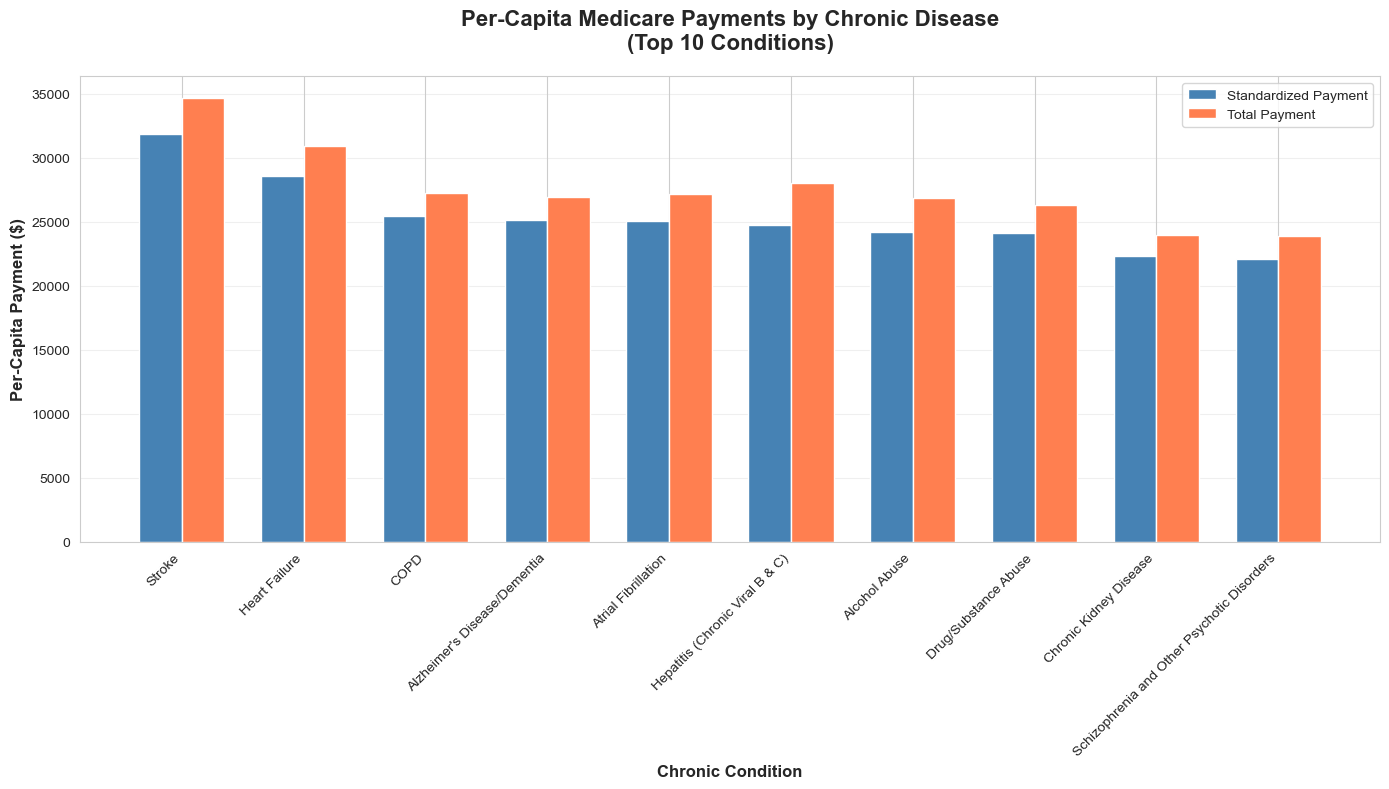


Medicare Payment Summary (Top 10 Diseases):
                                      Bene_Cond  Tot_Mdcr_Stdzd_Pymt_PC  \
20                                       Stroke                31881.96   
13                                Heart Failure                28604.45   
6                                          COPD                25446.52   
1                  Alzheimer's Disease/Dementia                25100.21   
4                           Atrial Fibrillation                25027.87   
14              Hepatitis (Chronic Viral B & C)                24742.22   
0                                 Alcohol Abuse                24208.04   
11                         Drug/Substance Abuse                24078.03   
8                        Chronic Kidney Disease                22316.22   
19  Schizophrenia and Other Psychotic Disorders                22062.10   

    Tot_Mdcr_Pymt_PC  
20          34626.59  
13          30940.20  
6           27255.40  
1           26895.59  
4           27

In [59]:
# Get national payment data
df_payments = df_with_payments[df_with_payments['Bene_Geo_Lvl'] == 'National'].copy()

if len(df_payments) > 0:
    # Calculate average payments by disease
    payment_summary = df_payments.groupby('Bene_Cond').agg({
        'Tot_Mdcr_Stdzd_Pymt_PC': 'mean',
        'Tot_Mdcr_Pymt_PC': 'mean'
    }).reset_index()
    
    payment_summary = payment_summary.sort_values('Tot_Mdcr_Stdzd_Pymt_PC', ascending=False).head(10)
    
    # Create bar chart
    fig, ax = plt.subplots(figsize=(14, 8))
    x = np.arange(len(payment_summary))
    width = 0.35
    bars1 = ax.bar(x - width/2, payment_summary['Tot_Mdcr_Stdzd_Pymt_PC'], 
                   width, label='Standardized Payment', color='steelblue')
    bars2 = ax.bar(x + width/2, payment_summary['Tot_Mdcr_Pymt_PC'], 
                   width, label='Total Payment', color='coral')
    ax.set_title('Per-Capita Medicare Payments by Chronic Disease\n(Top 10 Conditions)', 
                 fontsize=16, fontweight='bold', pad=20)
    ax.set_xlabel('Chronic Condition', fontsize=12, fontweight='bold')
    ax.set_ylabel('Per-Capita Payment ($)', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(payment_summary['Bene_Cond'], rotation=45, ha='right')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('medicare_payments_by_disease.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\nMedicare Payment Summary (Top 10 Diseases):")
    print(payment_summary.round(2))

## Visualization 2.2: Medicare Utilization Patterns

### What This Shows
This line chart tracks Medicare payment trends, either across age groups (if available) or across different diseases, showing both standardized and actual payments.

### Key Insights to Look For
- **Payment trends**: How costs vary across categories
- **Standardization impact**: Where geographic cost adjustments matter most
- **High-utilization areas**: Categories with steepest cost increases

### Clinical Implications
- Older beneficiaries typically have higher utilization
- Understanding payment patterns helps with:
  - Staffing decisions
  - Service line planning
  - Budget forecasting

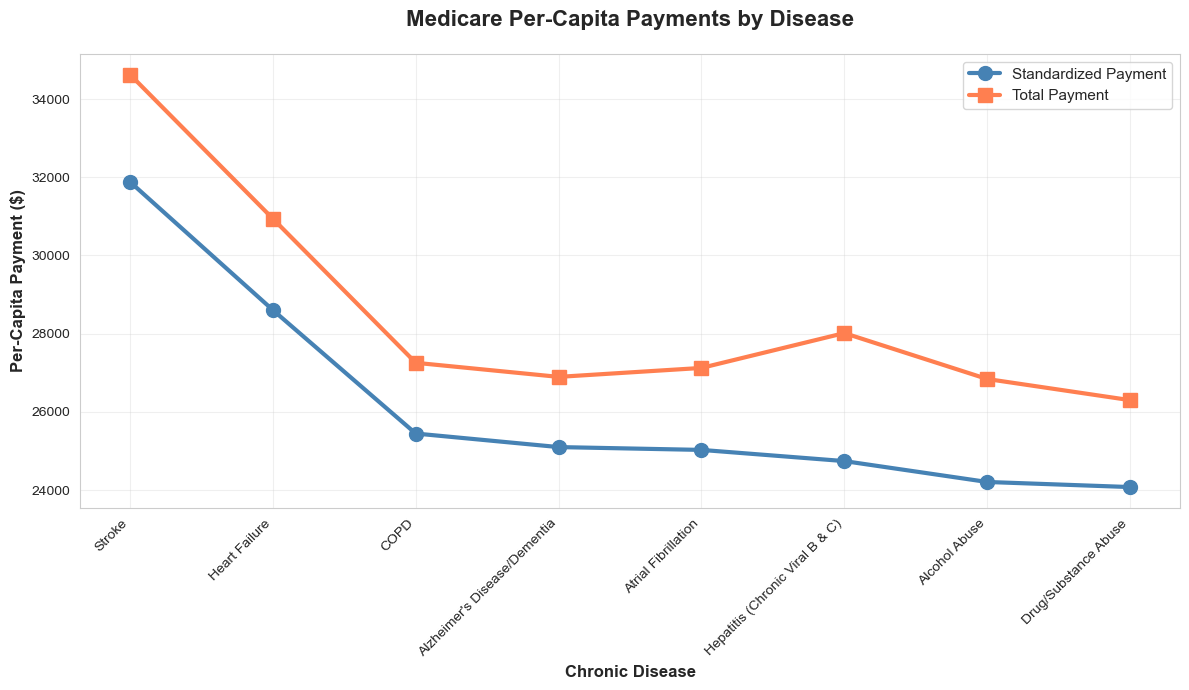


Medicare Payments by Disease:
                          Bene_Cond  Tot_Mdcr_Stdzd_Pymt_PC  Tot_Mdcr_Pymt_PC
20                           Stroke                31881.96          34626.59
13                    Heart Failure                28604.45          30940.20
6                              COPD                25446.52          27255.40
1      Alzheimer's Disease/Dementia                25100.21          26895.59
4               Atrial Fibrillation                25027.87          27124.24
14  Hepatitis (Chronic Viral B & C)                24742.22          28015.06
0                     Alcohol Abuse                24208.04          26841.00
11             Drug/Substance Abuse                24078.03          26300.77


In [60]:
# Get payment data
df_payments_age = df_with_payments[
    (df_with_payments['Bene_Geo_Lvl'] == 'National') & 
    (df_with_payments['Bene_Demo_Lvl'] == 'All')
].copy()

if len(df_payments_age) > 0:
    age_payments = df_payments_age.groupby('Bene_Age_Lvl').agg({
        'Tot_Mdcr_Stdzd_Pymt_PC': 'mean',
        'Tot_Mdcr_Pymt_PC': 'mean'
    }).reset_index()
    
    if len(age_payments) == 1 or (age_payments['Bene_Age_Lvl'] == 'All').all():
        disease_payments = df_payments_age.groupby('Bene_Cond').agg({
            'Tot_Mdcr_Stdzd_Pymt_PC': 'mean',
            'Tot_Mdcr_Pymt_PC': 'mean'
        }).reset_index().sort_values('Tot_Mdcr_Stdzd_Pymt_PC', ascending=False).head(8)
        
        fig, ax = plt.subplots(figsize=(12, 7))
        x = np.arange(len(disease_payments))
        ax.plot(x, disease_payments['Tot_Mdcr_Stdzd_Pymt_PC'], 
                marker='o', linewidth=3, markersize=10, label='Standardized Payment', color='steelblue')
        ax.plot(x, disease_payments['Tot_Mdcr_Pymt_PC'], 
                marker='s', linewidth=3, markersize=10, label='Total Payment', color='coral')
        ax.set_title('Medicare Per-Capita Payments by Disease', 
                     fontsize=16, fontweight='bold', pad=20)
        ax.set_xlabel('Chronic Disease', fontsize=12, fontweight='bold')
        ax.set_ylabel('Per-Capita Payment ($)', fontsize=12, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(disease_payments['Bene_Cond'], rotation=45, ha='right')
        ax.legend(fontsize=11)
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig('medicare_payments_by_disease_line.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        print("\nMedicare Payments by Disease:")
        print(disease_payments.round(2))

## Visualization 2.3: State-Level Medicare Payment Comparison

### What This Shows
This chart compares average Medicare per-capita payments in Texas, New York, California, and Florida against the national average.

### Key Insights to Look For
- **State cost variations**: Which states have higher or lower Medicare spending
- **Geographic payment differences**: Impact of regional cost factors
- **Standardization effects**: How geographic adjustments affect payments

### Strategic Value
Hospital leadership can use this to:
- Benchmark against national averages
- Understand reimbursement environments
- Plan for state-specific cost structures
- Identify opportunities for cost efficiency

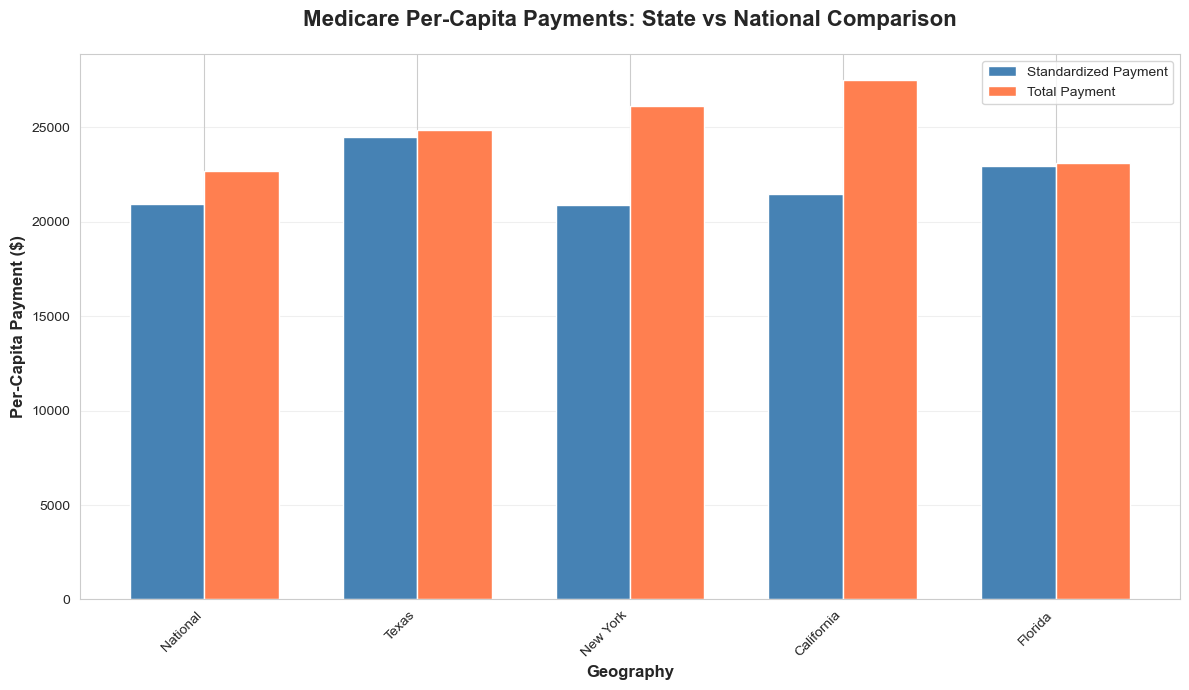


State vs National Medicare Payment Comparison:
               Tot_Mdcr_Stdzd_Pymt_PC  Tot_Mdcr_Pymt_PC
Bene_Geo_Desc                                          
National                     20962.73          22698.92
Texas                        24515.94          24873.52
New York                     20891.91          26144.08
California                   21455.63          27520.35
Florida                      22943.60          23111.51


In [61]:
# Get state payment data
df_state_payments = df_with_payments[
    (df_with_payments['Bene_Geo_Desc'].isin(target_states + ['National']))
].copy()

if len(df_state_payments) > 0:
    state_payment_summary = df_state_payments.groupby('Bene_Geo_Desc').agg({
        'Tot_Mdcr_Stdzd_Pymt_PC': 'mean',
        'Tot_Mdcr_Pymt_PC': 'mean'
    }).reset_index()
    
    state_payment_summary = state_payment_summary.set_index('Bene_Geo_Desc')
    
    available_geos = [g for g in ['National'] + target_states if g in state_payment_summary.index]
    state_payment_summary = state_payment_summary.reindex(available_geos)
    
    fig, ax = plt.subplots(figsize=(12, 7))
    x = np.arange(len(state_payment_summary))
    width = 0.35
    bars1 = ax.bar(x - width/2, state_payment_summary['Tot_Mdcr_Stdzd_Pymt_PC'], 
                   width, label='Standardized Payment', color='steelblue')
    bars2 = ax.bar(x + width/2, state_payment_summary['Tot_Mdcr_Pymt_PC'], 
                   width, label='Total Payment', color='coral')
    ax.set_title('Medicare Per-Capita Payments: State vs National Comparison', 
                 fontsize=16, fontweight='bold', pad=20)
    ax.set_xlabel('Geography', fontsize=12, fontweight='bold')
    ax.set_ylabel('Per-Capita Payment ($)', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(state_payment_summary.index, rotation=45, ha='right')
    ax.legend()
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig('state_medicare_payments.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\nState vs National Medicare Payment Comparison:")
    print(state_payment_summary.round(2))

# Goal 3: Identify State-Level Differences in Disease Prevalence

## Objective
Compare chronic disease prevalence across all 50 states to identify geographic patterns, rank state performance, and highlight how Texas, New York, California, and Florida compare to other states.

## Key Questions
1. Which states have the highest and lowest prevalence for each disease?
2. Where do our target states rank nationally?
3. Are there regional patterns in disease burden?
4. What gender-specific patterns exist across states?


## Visualization 3.1: State Rankings by Disease

### What This Shows
These four panels display the top 10 states with the highest prevalence for each of the top 4 chronic diseases. Target states (Texas, New York, California, Florida) are highlighted in red.

### Key Insights to Look For
- **State rankings**: Where target states rank nationally for each condition
- **Geographic patterns**: Whether certain regions cluster together
- **Outliers**: States with exceptionally high or low prevalence

### How to Interpret
- **Red bars** = One of our four target states
- **Blue bars** = Other states
- **Bar length** = Disease prevalence percentage
- Rankings are from highest to lowest (top to bottom)

### Action Items
States with high rankings may need:
- Enhanced disease management programs
- Additional specialist capacity
- Targeted public health interventions

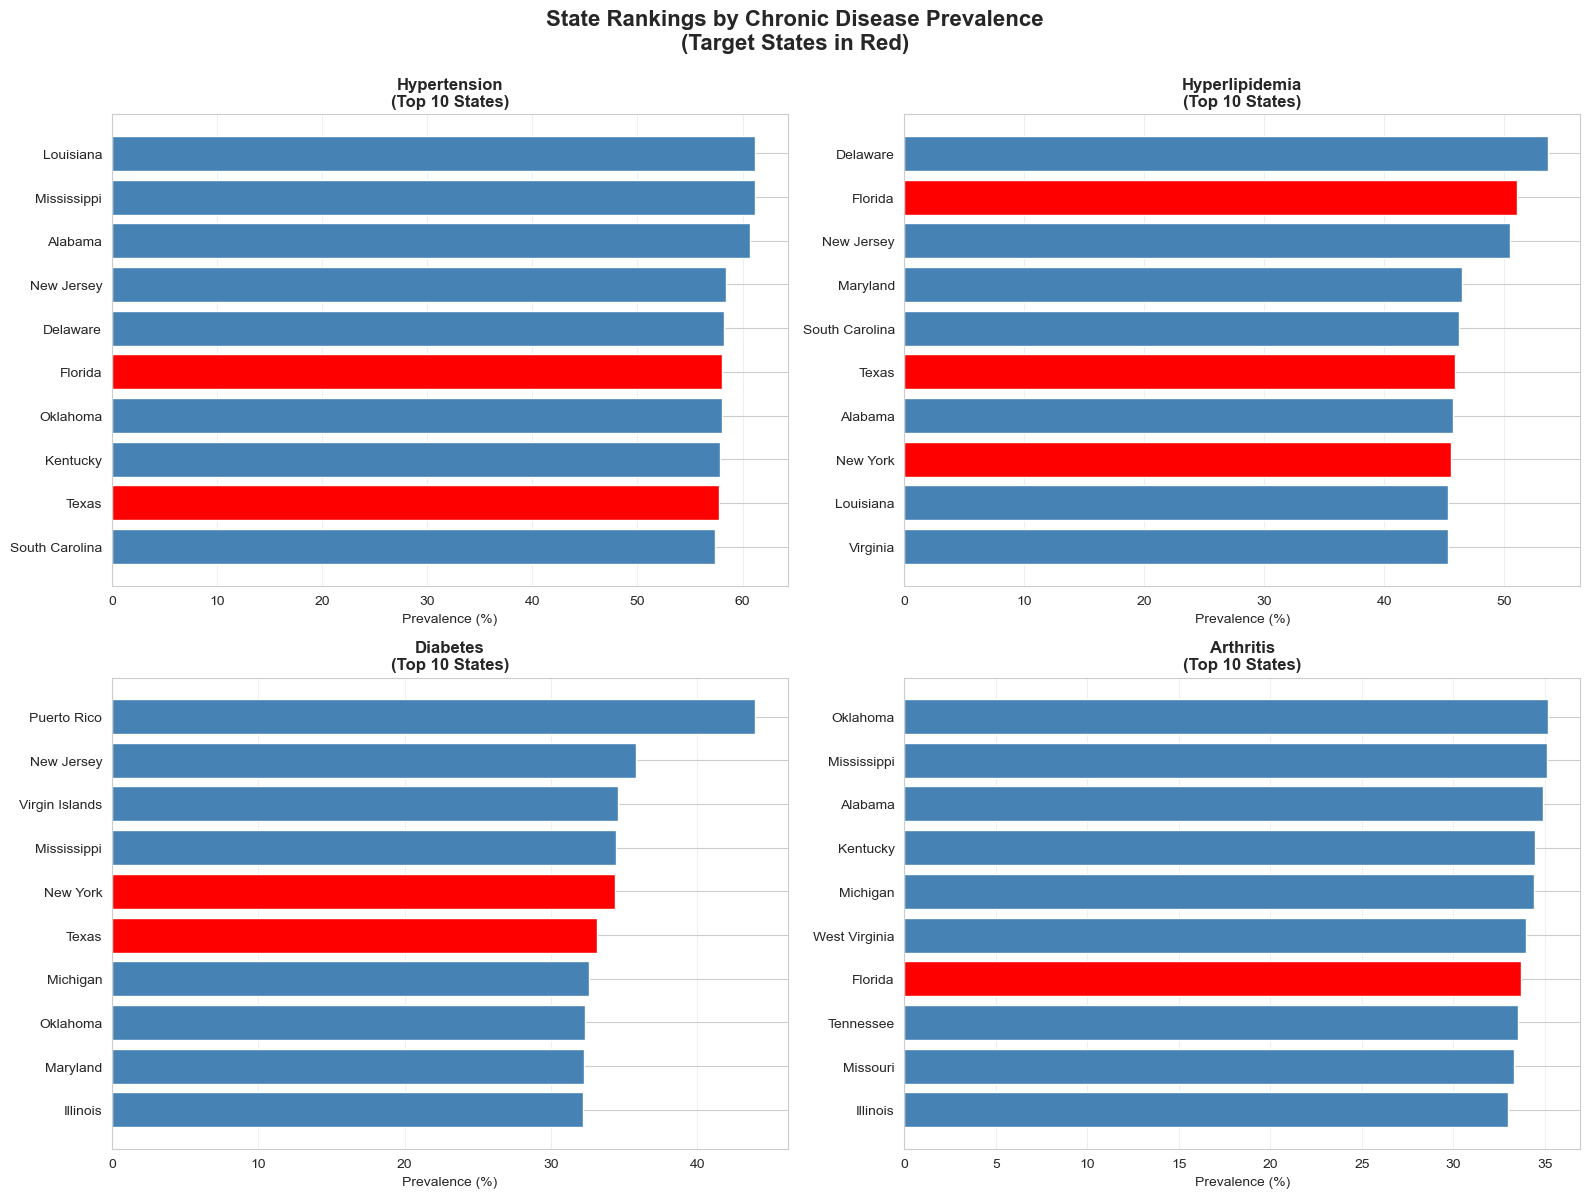

In [62]:
# Get state-level data
df_states = df_with_prevalence[df_with_prevalence['Bene_Geo_Lvl'] == 'State'].copy()

if len(df_states) > 0:
    state_disease_prevalence = df_states.groupby(['Bene_Geo_Desc', 'Bene_Cond'])['Prvlnc'].mean().reset_index()
    
    national_top = df_with_prevalence[df_with_prevalence['Bene_Geo_Lvl'] == 'National'].groupby('Bene_Cond')['Prvlnc'].mean().nlargest(4)
    top_4_diseases = national_top.index.tolist()
    
    state_disease_top = state_disease_prevalence[state_disease_prevalence['Bene_Cond'].isin(top_4_diseases)]
    
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    axes = axes.flatten()
    
    for idx, disease in enumerate(top_4_diseases):
        disease_data = state_disease_top[state_disease_top['Bene_Cond'] == disease].sort_values('Prvlnc', ascending=False).head(10)
        
        if len(disease_data) > 0:
            colors = ['red' if state in target_states else 'steelblue' for state in disease_data['Bene_Geo_Desc']]
            
            axes[idx].barh(disease_data['Bene_Geo_Desc'], disease_data['Prvlnc'], color=colors)
            axes[idx].set_title(f'{disease}\n(Top 10 States)', fontsize=12, fontweight='bold')
            axes[idx].set_xlabel('Prevalence (%)', fontsize=10)
            axes[idx].invert_yaxis()
            axes[idx].grid(axis='x', alpha=0.3)
    
    plt.suptitle('State Rankings by Chronic Disease Prevalence\n(Target States in Red)', 
                 fontsize=16, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.savefig('state_rankings.png', dpi=300, bbox_inches='tight')
    plt.show()

## Visualization 3.2: Gender-Specific Prevalence by State

### What This Shows
These three side-by-side charts compare disease prevalence between males and females across our target states and the national average for the top 3 chronic conditions.

### Key Insights to Look For
- **Gender disparities**: Which diseases show larger differences between males and females
- **State patterns**: Whether gender gaps are consistent across states
- **Clinical implications**: Gender-specific risk factors and screening needs

### How to Read This
- Two bars per state (one for each gender)
- Direct comparison within each state
- Light blue = One gender, Light coral = Other gender
- Compare bar heights to see gender differences

### Healthcare Planning Implications
Understanding gender-specific patterns helps with:
- Targeted screening programs
- Gender-appropriate treatment protocols
- Resource allocation by gender demographics

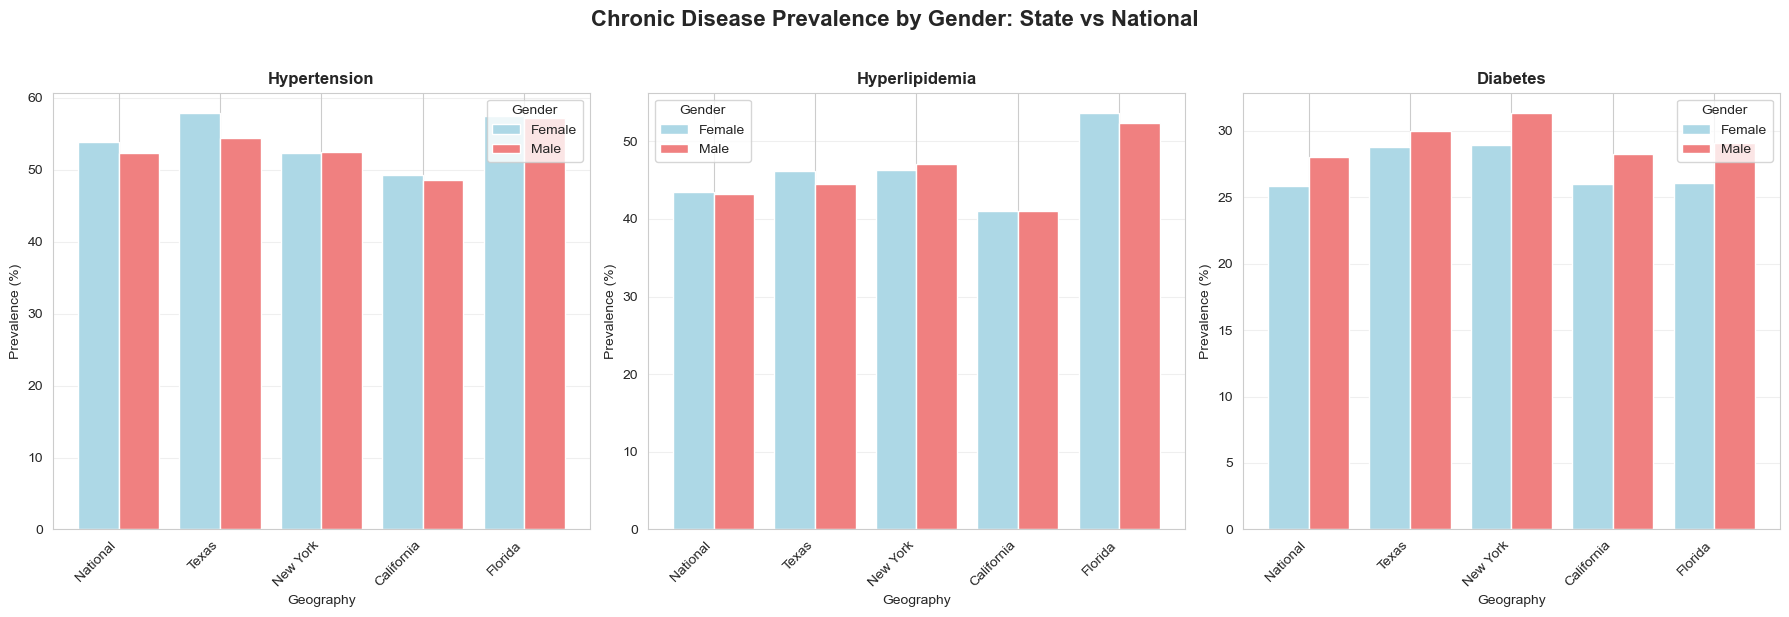

In [63]:
# Get gender data
df_gender = df_with_prevalence[
    (df_with_prevalence['Bene_Demo_Lvl'] == 'Sex') &
    (df_with_prevalence['Bene_Geo_Desc'].isin(target_states + ['National']))
].copy()

if len(df_gender) > 0:
    gender_prevalence = df_gender.groupby(['Bene_Geo_Desc', 'Bene_Demo_Desc', 'Bene_Cond'])['Prvlnc'].mean().reset_index()
    
    top_3_diseases = df_with_prevalence[df_with_prevalence['Bene_Geo_Lvl'] == 'National'].groupby('Bene_Cond')['Prvlnc'].mean().nlargest(3).index.tolist()
    gender_prevalence_top = gender_prevalence[gender_prevalence['Bene_Cond'].isin(top_3_diseases)]
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    for idx, disease in enumerate(top_3_diseases):
        disease_gender = gender_prevalence_top[gender_prevalence_top['Bene_Cond'] == disease]
        
        if len(disease_gender) > 0:
            disease_pivot = disease_gender.pivot(index='Bene_Geo_Desc', columns='Bene_Demo_Desc', values='Prvlnc')
            
            available_geos = [g for g in ['National'] + target_states if g in disease_pivot.index]
            disease_pivot = disease_pivot.reindex(available_geos)
            disease_pivot = disease_pivot.fillna(0)
            
            disease_pivot.plot(kind='bar', ax=axes[idx], width=0.8, color=['lightblue', 'lightcoral'])
            axes[idx].set_title(f'{disease}', fontsize=12, fontweight='bold')
            axes[idx].set_xlabel('Geography', fontsize=10)
            axes[idx].set_ylabel('Prevalence (%)', fontsize=10)
            axes[idx].set_xticklabels(axes[idx].get_xticklabels(), rotation=45, ha='right')
            axes[idx].legend(title='Gender')
            axes[idx].grid(axis='y', alpha=0.3)
    
    plt.suptitle('Chronic Disease Prevalence by Gender: State vs National', 
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('gender_state_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()

## Visualization 3.3: State Deviation from National Average

### What This Shows
This heatmap displays how much each target state's disease prevalence differs from the national average. Positive values (red) indicate prevalence above the national average, while negative values (green) indicate prevalence below the national average.

### Key Insights to Look For
- **Red cells**: States with higher-than-average disease burden
- **Green cells**: States with lower-than-average disease burden
- **Intensity of color**: Magnitude of the difference from national average
- **Patterns across diseases**: Whether states consistently run above or below average

### Strategic Implications
States showing **positive deviations** (red) may need:
- Additional healthcare resources and staffing
- Enhanced disease management programs
- Investigation into underlying causes (demographics, social determinants, access to care)

States showing **negative deviations** (green) may have:
- Effective prevention programs worth studying
- Different population demographics
- Potential underdiagnosis requiring attention

### How to Read This Chart
- **Each cell** = Percentage point difference from national average
- **Example**: +2.5% means the state's prevalence is 2.5 percentage points higher than national
- **Zero** (white/neutral) = State matches national average exactly

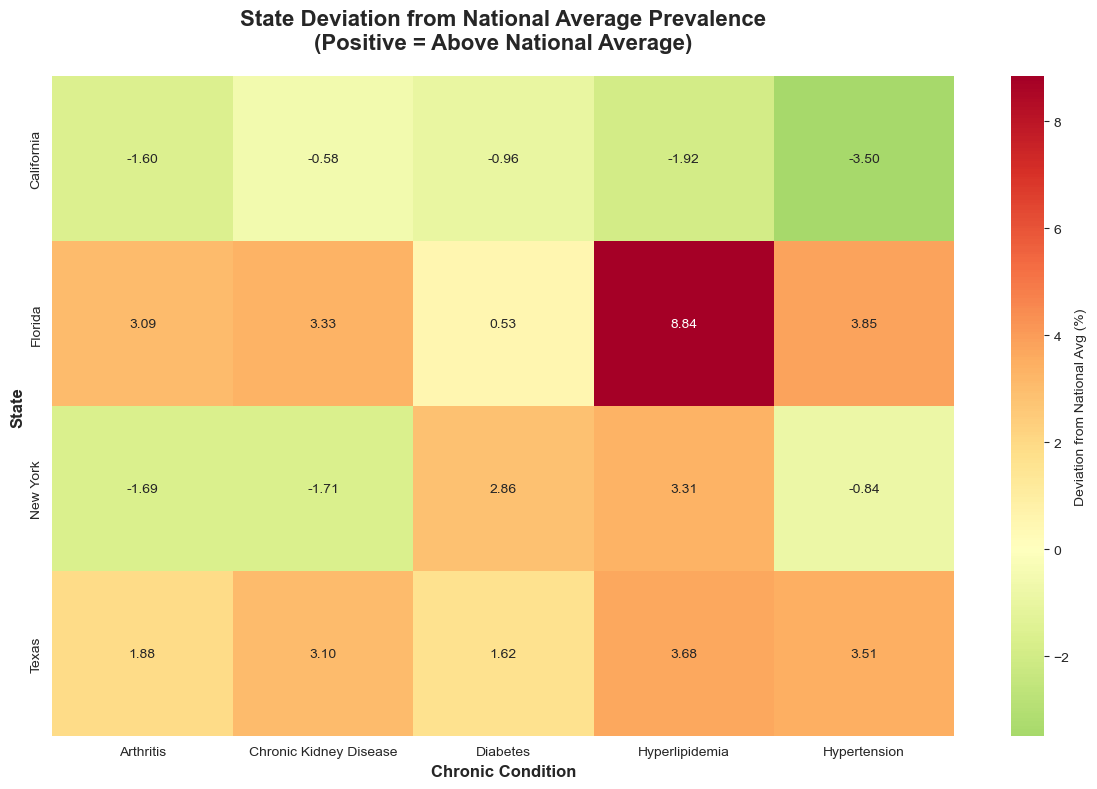


State Deviation from National Average:
Bene_Cond      Arthritis  Chronic Kidney Disease  Diabetes  Hyperlipidemia  \
Bene_Geo_Desc                                                                
California         -1.60                   -0.58     -0.96           -1.92   
Florida             3.09                    3.33      0.53            8.84   
New York           -1.69                   -1.71      2.86            3.31   
Texas               1.88                    3.10      1.62            3.68   

Bene_Cond      Hypertension  
Bene_Geo_Desc                
California            -3.50  
Florida                3.85  
New York              -0.84  
Texas                  3.51  


In [64]:
if len(df_states) > 0:
    # Calculate average prevalence by state and disease
    state_disease_prevalence = df_states.groupby(['Bene_Geo_Desc', 'Bene_Cond'])['Prvlnc'].mean().reset_index()
    
    # Get national averages
    national_data = df_with_prevalence[df_with_prevalence['Bene_Geo_Lvl'] == 'National'].groupby('Bene_Cond')['Prvlnc'].mean().reset_index()
    national_data.columns = ['Bene_Cond', 'National_Avg']
    
    # Merge and calculate deviation
    national_avg = state_disease_prevalence.merge(national_data, on='Bene_Cond', how='left')
    national_avg['Deviation'] = national_avg['Prvlnc'] - national_avg['National_Avg']
    
    # Get top 5 diseases
    top_5_diseases = national_data.nlargest(5, 'National_Avg')['Bene_Cond'].tolist()
    
    # Focus on target states and top diseases
    target_deviation = national_avg[
        (national_avg['Bene_Geo_Desc'].isin(target_states)) &
        (national_avg['Bene_Cond'].isin(top_5_diseases))
    ]
    
    if len(target_deviation) > 0:
        # Create heatmap
        fig, ax = plt.subplots(figsize=(12, 8))
        deviation_pivot = target_deviation.pivot(index='Bene_Geo_Desc', columns='Bene_Cond', values='Deviation')
        deviation_pivot = deviation_pivot.fillna(0)
        
        sns.heatmap(deviation_pivot, annot=True, fmt='.2f', cmap='RdYlGn_r', center=0,
                    cbar_kws={'label': 'Deviation from National Avg (%)'}, ax=ax)
        ax.set_title('State Deviation from National Average Prevalence\n(Positive = Above National Average)', 
                     fontsize=16, fontweight='bold', pad=20)
        ax.set_xlabel('Chronic Condition', fontsize=12, fontweight='bold')
        ax.set_ylabel('State', fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.savefig('state_deviation.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        print("\nState Deviation from National Average:")
        print(deviation_pivot.round(2))
    else:
        print("Warning: No deviation data available for target states")
else:
    print("Warning: No state data available for deviation analysis")

# Additional cells: age analysis, summary tables, rankings

# Summary Tables (Deliverables)
The tables below summarize prevalence and Medicare payments for the national level and the four target states, in plain numbers suitable for leadership. Prevalence is the percent of beneficiaries with the condition.

## Table 1: National Prevalence by Condition, Race and Sex (%)

In [65]:
nat_prev = df_with_prevalence[df_with_prevalence['Bene_Geo_Lvl'] == 'National']

t1_all = nat_prev[nat_prev['Bene_Demo_Lvl'] == 'All'].groupby('Bene_Cond')['Prvlnc'].mean().rename('All beneficiaries')
t1_race = (nat_prev[nat_prev['Bene_Demo_Lvl'] == 'Race']
           .pivot_table(index='Bene_Cond', columns='Bene_Demo_Desc', values='Prvlnc', aggfunc='mean'))
t1_sex = (nat_prev[nat_prev['Bene_Demo_Lvl'] == 'Sex']
          .pivot_table(index='Bene_Cond', columns='Bene_Demo_Desc', values='Prvlnc', aggfunc='mean'))

table1 = pd.concat([t1_all, t1_race, t1_sex], axis=1).sort_values('All beneficiaries', ascending=False).round(1)
table1

,All beneficiaries,Asian Pacific Islander,Hispanic,Native American,non-Hispanic Black,non-Hispanic White,Female,Male
Bene_Cond,,,,,,,,
Hypertension,57.2,51.8,51.6,52.9,62.7,52.0,53.9,52.3
Hyperlipidemia,47.7,46.3,41.8,33.3,40.7,43.9,43.5,43.2
Arthritis,33.5,22.4,28.0,31.9,31.1,32.6,37.4,25.4
Diabetes,27.0,34.9,36.8,39.1,36.6,24.4,25.9,28.0
Ischemic Heart Disease,26.8,20.5,22.1,23.5,23.1,24.6,20.3,28.6
Chronic Kidney Disease,24.5,26.4,28.1,29.3,32.3,22.2,22.7,25.2
Depression,18.4,13.1,20.2,22.4,17.1,23.6,27.6,16.1
Heart Failure,14.0,10.6,12.6,14.3,17.0,12.6,12.5,13.6
COPD,11.5,6.2,7.8,12.6,10.2,12.7,12.1,11.2


## Table 2: Prevalence for Target States versus National (%)

In [66]:
geo = ['National'] + target_states
t2 = (df_with_prevalence[(df_with_prevalence['Bene_Demo_Lvl'] == 'All') &
                         (df_with_prevalence['Bene_Geo_Desc'].isin(geo))]
      .pivot_table(index='Bene_Cond', columns='Bene_Geo_Desc', values='Prvlnc', aggfunc='mean')[geo])
table2 = t2.round(1)
table2

Bene_Geo_Desc,National,Texas,New York,California,Florida
Bene_Cond,,,,,
Alcohol Abuse,2.1,1.8,2.1,2.2,2.3
Alzheimer's Disease/Dementia,10.8,12.6,12.2,10.5,12.6
Arthritis,33.5,34.2,32.3,31.2,37.5
Asthma,5.0,4.9,5.9,5.3,5.2
Atrial Fibrillation,8.4,7.8,8.9,7.5,10.1
Autism Spectrum Disorders,0.3,0.2,0.5,0.2,0.2
COPD,11.5,11.2,11.0,9.5,13.5
Cancer,8.4,7.6,9.5,7.8,10.1
Chronic Kidney Disease,24.5,26.7,23.4,24.3,28.2


## Table 3: Difference from the National Rate, in Percentage Points
Positive values mean the state is above the national rate. Sorted by the largest absolute gap in any target state, which answers which diseases differ most from the national average.

In [67]:
diff = t2[target_states].sub(t2['National'], axis=0)
table3 = diff.loc[diff.abs().max(axis=1).sort_values(ascending=False).index].round(1)
table3

Bene_Geo_Desc,Texas,New York,California,Florida
Bene_Cond,,,,
Hyperlipidemia,1.8,3.5,-2.4,11.5
Ischemic Heart Disease,2.2,3.0,-2.1,7.5
Hypertension,2.7,0.5,-4.2,5.2
Diabetes,1.8,4.4,0.2,0.9
Arthritis,0.7,-1.1,-2.3,4.0
Chronic Kidney Disease,2.2,-1.0,-0.2,3.7
Depression,-0.2,-1.4,-2.2,1.1
COPD,-0.3,-0.4,-1.9,2.0
Alzheimer's Disease/Dementia,1.8,1.4,-0.3,1.8


## Table 4: Prevalence by Race for Each Target State (%)

In [68]:
race_state = (df_with_prevalence[(df_with_prevalence['Bene_Demo_Lvl'] == 'Race') &
                                 (df_with_prevalence['Bene_Geo_Desc'].isin(target_states)) &
                                 (df_with_prevalence['Bene_Cond'].isin(top_diseases))]
              .pivot_table(index=['Bene_Geo_Desc', 'Bene_Cond'], columns='Bene_Demo_Desc',
                           values='Prvlnc', aggfunc='mean').round(1))
race_state

Bene_Demo_Desc                        Asian Pacific Islander  Hispanic  \
Bene_Geo_Desc Bene_Cond                                                  
California    Arthritis                                 24.3      25.8   
              Chronic Kidney Disease                    28.5      28.3   
              Diabetes                                  36.4      37.6   
              Hyperlipidemia                            48.1      39.7   
              Hypertension                              54.6      50.2   
              Ischemic Heart Disease                    22.3      20.3   
Florida       Arthritis                                 24.3      34.5   
              Chronic Kidney Disease                    27.3      31.5   
              Diabetes                                  34.3      36.4   
              Hyperlipidemia                            50.6      52.3   
              Hypertension                              53.1      58.5   
              Ischemic Heart Disease                    24.6      32.0   
New York      Arthritis                                 26.8      26.7   
              Chronic Kidney Disease                    27.4      24.3   
              Diabetes                                  40.5      36.5   
              Hyperlipidemia                            51.4      42.2   
              Hypertension                              54.4      50.8   
              Ischemic Heart Disease                    26.6      23.7   
Texas         Arthritis                                 23.4      30.2   
              Chronic Kidney Disease                    28.5      34.5   
              Diabetes                                  35.8      41.3   
              Hyperlipidemia                            49.3      47.6   
              Hypertension                              53.4      57.3   
              Ischemic Heart Disease                    21.7      26.1   

Bene_Demo_Desc                        Native American  non-Hispanic Black  \
Bene_Geo_Desc Bene_Cond                                                     
California    Arthritis                          31.4                30.0   
              Chronic Kidney Disease             27.6                30.7   
              Diabetes                           34.8                32.9   
              Hyperlipidemia                     33.7                34.4   
              Hypertension                       49.7                55.7   
              Ischemic Heart Disease             22.7                23.3   
Florida       Arthritis                          35.9                29.9   
              Chronic Kidney Disease             31.8                36.9   
              Diabetes                           37.9                38.9   
              Hyperlipidemia                     45.6                46.1   
              Hypertension                       56.5                63.5   
              Ischemic Heart Disease             32.2                28.4   
New York      Arthritis                          29.2                25.9   
              Chronic Kidney Disease             26.7                29.5   
              Diabetes                           40.9                39.0   
              Hyperlipidemia                     39.6                39.9   
              Hypertension                       50.5                58.1   
              Ischemic Heart Disease             27.9                24.3   
Texas         Arthritis                          38.1                33.2   
              Chronic Kidney Disease             29.3                35.3   
              Diabetes                           35.0                36.9   
              Hyperlipidemia                     44.2                43.0   
              Hypertension                       58.8                63.8   
              Ischemic Heart Disease             27.6                25.8   

Bene_Demo_Desc                        non-Hispanic White  
Bene_Geo_Desc

## Table 5: Medicare Payments per Beneficiary, National versus Target States
Per-capita amounts for the "All beneficiaries" group. Standardized payments remove regional price differences, so they are the fairer comparison between states.

In [69]:
pay = df_with_payments[(df_with_payments['Bene_Demo_Lvl'] == 'All') &
                       (df_with_payments['Bene_Geo_Desc'].isin(geo))]

table5a = (pay.pivot_table(index='Bene_Cond', columns='Bene_Geo_Desc',
                           values='Tot_Mdcr_Stdzd_Pymt_PC', aggfunc='mean')[geo]
           .sort_values('National', ascending=False).round(0))
print("Standardized payment per beneficiary ($), by condition")
display(table5a)

table5b = (pay.pivot_table(index='Bene_Cond', columns='Bene_Geo_Desc',
                           values='Tot_Mdcr_Pymt_PC', aggfunc='mean')[geo]
           .reindex(table5a.index).round(0))
print("Total payment per beneficiary ($), by condition")
display(table5b)

Standardized payment per beneficiary ($), by condition


Bene_Geo_Desc,National,Texas,New York,California,Florida
Bene_Cond,,,,,
Stroke,31882.0,37209.0,31004.0,33832.0,32991.0
Heart Failure,28604.0,32811.0,28507.0,28974.0,31317.0
COPD,25447.0,30228.0,25853.0,27690.0,27394.0
Alzheimer's Disease/Dementia,25100.0,30397.0,24748.0,25626.0,28260.0
Atrial Fibrillation,25028.0,29705.0,25750.0,25355.0,27002.0
Hepatitis (Chronic Viral B & C),24742.0,29492.0,24849.0,21343.0,27159.0
Alcohol Abuse,24208.0,29180.0,22834.0,25617.0,27107.0
Drug/Substance Abuse,24078.0,27321.0,23403.0,26038.0,28090.0
Chronic Kidney Disease,22316.0,25610.0,23563.0,22495.0,22980.0


Total payment per beneficiary ($), by condition


Bene_Geo_Desc,National,Texas,New York,California,Florida
Bene_Cond,,,,,
Stroke,34627.0,37578.0,39452.0,44002.0,33134.0
Heart Failure,30940.0,33203.0,35919.0,37330.0,31500.0
COPD,27255.0,30510.0,31919.0,35450.0,27452.0
Alzheimer's Disease/Dementia,26896.0,30385.0,31433.0,33052.0,28138.0
Atrial Fibrillation,27124.0,30133.0,32068.0,32832.0,27151.0
Hepatitis (Chronic Viral B & C),28015.0,31034.0,32374.0,28030.0,27887.0
Alcohol Abuse,26841.0,30116.0,29054.0,34133.0,27364.0
Drug/Substance Abuse,26301.0,27968.0,29427.0,33960.0,28441.0
Chronic Kidney Disease,23983.0,25887.0,29315.0,28778.0,23073.0


## Table 6: Highest and Lowest States for Each Condition, with Target State Ranks
Rank 1 is the highest prevalence among the states in the file. This lists the highest and lowest state for every condition and shows where Texas, New York, California and Florida fall.

In [70]:
st = (df_with_prevalence[(df_with_prevalence['Bene_Geo_Lvl'] == 'State') &
                         (df_with_prevalence['Bene_Demo_Lvl'] == 'All')]
      .groupby(['Bene_Cond', 'Bene_Geo_Desc'])['Prvlnc'].mean().reset_index())
st['Rank'] = st.groupby('Bene_Cond')['Prvlnc'].rank(ascending=False, method='min').astype(int)
n_states = st['Bene_Geo_Desc'].nunique()

rows = []
for cond, g in st.groupby('Bene_Cond'):
    hi, lo = g.loc[g['Prvlnc'].idxmax()], g.loc[g['Prvlnc'].idxmin()]
    row = {'Condition': cond,
           'Highest state': f"{hi['Bene_Geo_Desc']} ({hi['Prvlnc']:.1f}%)",
           'Lowest state': f"{lo['Bene_Geo_Desc']} ({lo['Prvlnc']:.1f}%)"}
    for s in target_states:
        r = g.loc[g['Bene_Geo_Desc'] == s, 'Rank']
        row[f'{s} rank'] = int(r.iloc[0]) if len(r) else None
    rows.append(row)

table6 = pd.DataFrame(rows).set_index('Condition')
print(f"Ranks are out of {n_states} states/territories in the file (1 = highest prevalence)")
table6

Ranks are out of 53 states/territories in the file (1 = highest prevalence)


,Highest state,Lowest state,Texas rank,New York rank,California rank,Florida rank
Condition,,,,,,
Alcohol Abuse,Massachusetts (3.7%),Puerto Rico (0.7%),39,21,16,15
Alzheimer's Disease/Dementia,Puerto Rico (14.0%),Virgin Islands (7.3%),4,6,25,5
Arthritis,Alabama (39.0%),Virgin Islands (18.2%),18,27,31,4
Asthma,Puerto Rico (7.6%),Virgin Islands (1.7%),23,6,13,16
Atrial Fibrillation,Connecticut (10.7%),Virgin Islands (3.0%),32,12,40,2
Autism Spectrum Disorders,Minnesota (0.8%),Puerto Rico (0.0%),37,2,31,41
COPD,West Virginia (17.5%),Virgin Islands (1.9%),22,23,38,8
Cancer,Florida (10.1%),New Mexico (6.2%),37,5,30,1
Chronic Kidney Disease,Puerto Rico (31.6%),Wyoming (15.6%),5,30,25,2


## Export the Tables
Saves every table to one Excel workbook so they can be pasted into the Word report. Requires `openpyxl` (`pip install openpyxl`).

In [71]:
with pd.ExcelWriter('figures/summary_tables.xlsx') as xl:
    table1.to_excel(xl, sheet_name='1 National by race and sex')
    table2.to_excel(xl, sheet_name='2 States vs national')
    table3.to_excel(xl, sheet_name='3 Difference from national')
    race_state.to_excel(xl, sheet_name='4 Race by state')
    table5a.to_excel(xl, sheet_name='5a Standardized payment')
    table5b.to_excel(xl, sheet_name='5b Total payment')
    table6.to_excel(xl, sheet_name='6 State rankings')
print("Saved figures/summary_tables.xlsx")

Saved figures/summary_tables.xlsx
